Trajectory inference with CellRank

In this notebook, we include the main analysis for trajectory inference with CellRank. Important note: all the steps for performing the analysis have been generated with ChatGPT, and cross-checks must be taken into account. 

The data consists of the single-cell RNAseq CLL dataset from Cadot et al 2020 publication. The main goal of this analyis relies on indetifying cell trajectories and cell fates based on the transcriptomic profile of the cells. Of note, CellRank uses both RNA velocity and transcriptomics data to infer the trajectories and estimate the cell fates. In the absence of RNA velocity data, we conducted the analysis using only CLL transcriptomics profile. 

1. Load the necessary libraries

In [1]:
import scanpy as sc
import cellrank as cr
import numpy as np
import pandas as pd

sc.settings.verbosity = 3


2. Load the data as a `h5ad` object

In [2]:
adata = sc.read_h5ad("../Data/CLL_only/CLL_data.h5ad")
adata

AnnData object with n_obs × n_vars = 10570 × 33694
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_ADT', 'nFeature_ADT', 'time_point', 'RNA_snn_res.0.5', 'seurat_clusters', 'cell_types', 'nCount_tfsulm', 'nFeature_tfsulm'
    var: 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable'
    uns: 'neighbors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances'

In the following analysis, we make sure that the time annotation of the cells is done correctly (from the previous step, time is taken as a categorical object).

In [3]:
adata.obs['time_point'].value_counts().sort_index()
mapping = {0: "M0", 1: "M3", 2: "M27"}

adata.obs['time_point'] = (
    adata.obs['time_point']
    .map(mapping)
    .astype("category")
)

In [32]:
adata.obs[["time_point"]].to_csv("../Data/CLL_only/cell_time_annotation.csv")

In the following steps, we perform some extra analysis, including the selection of the top 2000 most variable genes to conduct the trajectory inference. 

In [4]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=20)

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    subset=True
)


filtered out 21635 genes that are detected in less than 20 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


Next, we perform the basic analysis to build a UMAP of the CLL cells.

In [5]:
sc.pp.scale(adata, max_value=10)

sc.tl.pca(adata, svd_solver="arpack")
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)

sc.tl.umap(adata)


... as `zero_center=True`, sparse input is densified and may lead to large memory consumption
computing PCA
    with n_comps=50
    finished (0:00:03)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:26)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:06)


FileNotFoundError: [Errno 2] No such file or directory: 'figures/umap../Plots/CLL_only/UMAP_timepoint_scanpy.png'

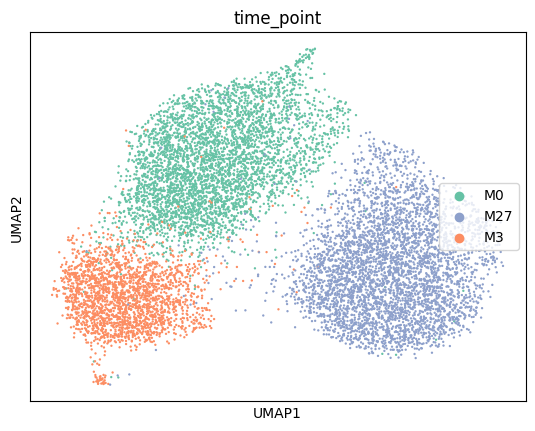

In [7]:
time_palette = {
    "M0":  "#66C2A5",
    "M3":  "#FC8D62",
    "M27": "#8DA0CB"
}
sc.pl.umap(
    adata,
    color="time_point",
    palette=time_palette,
    legend_loc="right",
    frameon=True,
    save = "../Plots/CLL_only/UMAP_timepoint_scanpy.png"#,
    #figsize = (2, 2)
)


The trajectory inference analysis starts here. 

In [7]:
ck = cr.kernels.ConnectivityKernel(adata)
ck.compute_transition_matrix()


ConnectivityKernel[n=10570, dnorm=True, key='connectivities']

The main macrostates are computed from employing a Generalised Perron Cluster Cluster Analysis (GPCCA) algorithm. We put an initial number of potential macrostates of `n_states = 5`, and let the algorithm detect how many real macrostates are in the system (usually it should be lower than the initial number)

In [8]:
g = cr.estimators.GPCCA(ck)

g.compute_schur(n_components=10)
g.compute_macrostates(n_states=5)


GPCCA[kernel=ConnectivityKernel[n=10570], initial_states=None, terminal_states=None]

/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/utils.py:1396: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/utils.py:1397: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ../Plots/CLL_only/all_macrostates_umap.png


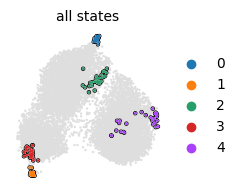

In [12]:
g.plot_macrostates(
    which="all",
    basis="umap",
    legend_loc="right",
    save = "../Plots/CLL_only/all_macrostates_umap.png",
    figsize = (2, 2)
)

And we see if here, were the terminal and initial states are choosen. We see that from the 5 macrostates we set in the beginning, only 3 of them correspond to initial and terminal ones. 

In [10]:
g.predict_terminal_states()
g.predict_initial_states()


GPCCA[kernel=ConnectivityKernel[n=10570], initial_states=['0'], terminal_states=['3', '4']]

saving figure to file ../Plots/CLL_only/terminal_macrostates_umap.png


/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/utils.py:1396: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/utils.py:1397: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


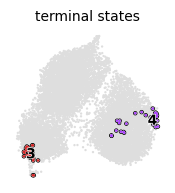

saving figure to file ../Plots/CLL_only/initial_macrostates_umap.png


/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/utils.py:1396: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/home/melanie/miniconda3/envs/trajectory/lib/python3.9/site-packages/scvelo/plotting/utils.py:1397: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


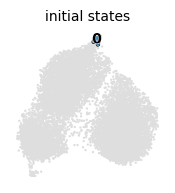

In [13]:
g.plot_macrostates(
    which="terminal",
    basis="umap",
    save = "../Plots/CLL_only/terminal_macrostates_umap.png",
    figsize = (2, 2)
)
g.plot_macrostates(
    which="initial",
    basis="umap",
    save = "../Plots/CLL_only/initial_macrostates_umap.png",
    figsize = (2, 2)
)

This is also a very important step: calculating the probabilities of a cell to go in one of the macrostates. We see that the cell associated to the initial states has a lower probability of staying in that state, whereas the cells associated/closer to the terminal states have a higher probability of staying there. 

In [14]:
g.compute_fate_probabilities()
g

Defaulting to `'gmres'` solver.


100%|███████████████████████████████████████████████| 2/2 [00:00<00:00,  7.35/s]


GPCCA[kernel=ConnectivityKernel[n=10570], initial_states=['0'], terminal_states=['3', '4']]

saving figure to file ../Plots/CLL_only/CLL_fate_probabilities_umap.png


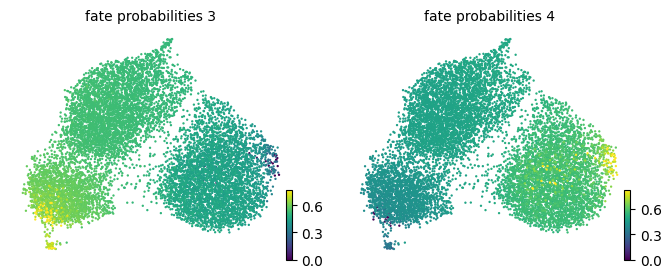

In [15]:
import matplotlib.pyplot as plt

fig = g.plot_fate_probabilities(
    basis="umap",
    same_plot=False,
    save = "../Plots/CLL_only/CLL_fate_probabilities_umap.png",
    figsize = (4, 3)
)



In [29]:
macro_probs = g.fate_probabilities 
macro_probs = pd.DataFrame(
    macro_probs,
    index=adata.obs_names
)

cell_matrix = np.dot(macro_probs.values, macro_probs.values.T)
cell_matrix = pd.DataFrame(cell_matrix, index=adata.obs_names, columns=adata.obs_names)

cell_matrix.to_csv("../Results/cell_matrix_fate_probabilities.csv")

In [30]:
macro_probs.to_csv("../Results/cell_matrix_fate_probabilities_light.csv")

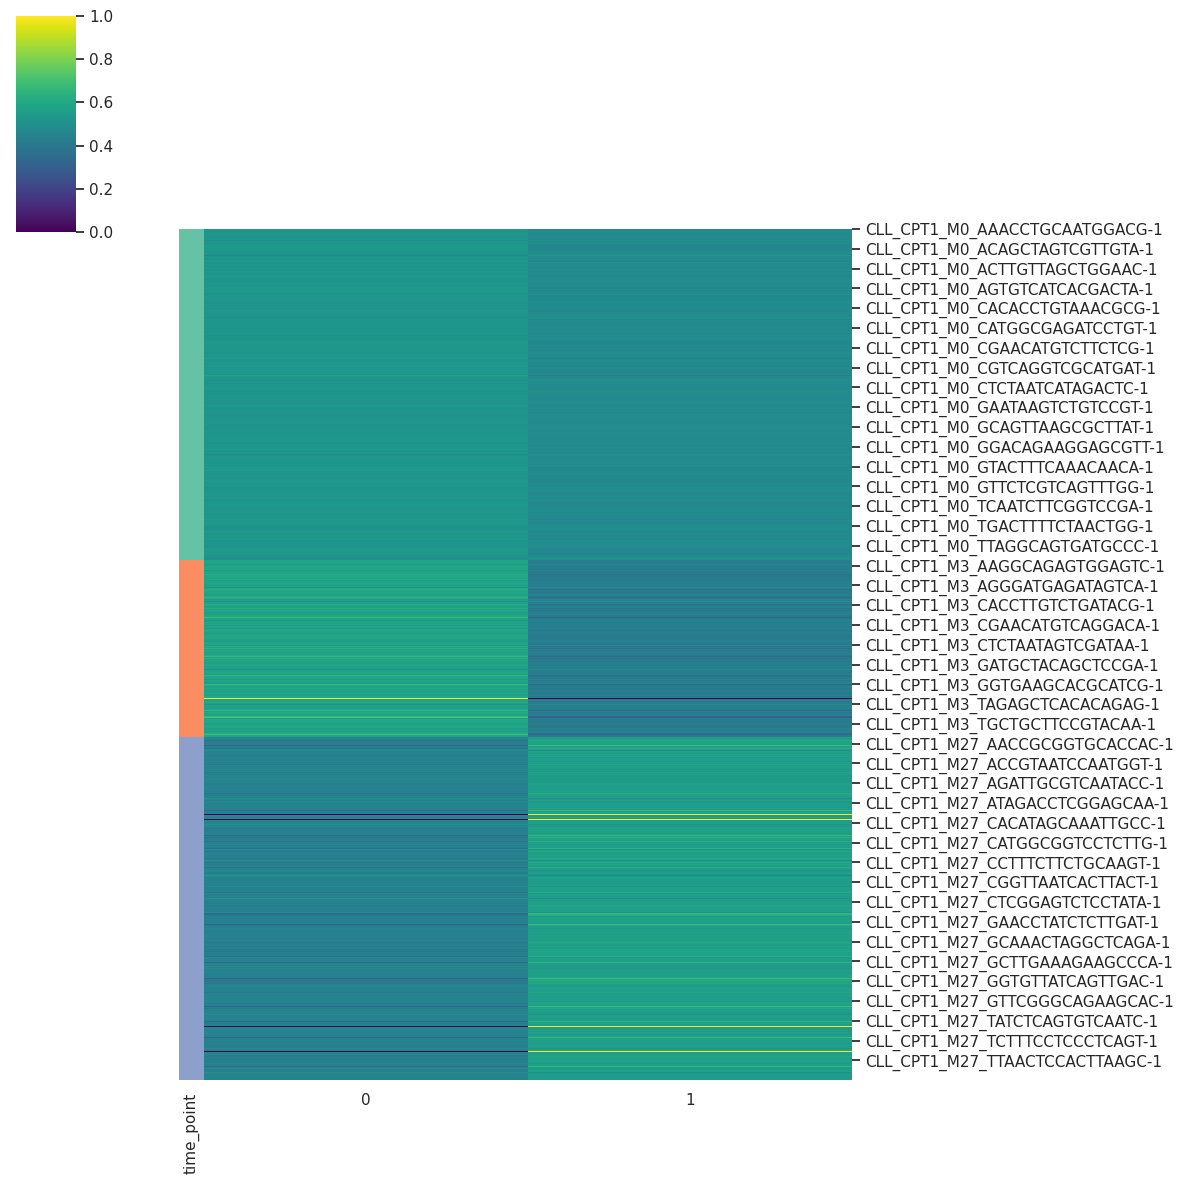

In [31]:
import seaborn as sns
# row colors for time points
row_colors = adata.obs["time_point"].map({
    "M0": "#66C2A5",
    "M3": "#FC8D62",
    "M27": "#8DA0CB"
})


sns.set(style="white")
sns.clustermap(
    macro_probs,
    row_cluster=False,
    col_cluster=False,
    row_colors=row_colors,
    #col_colors=row_colors,
    cmap="viridis",
    figsize=(12, 12)
)
plt.show()


The following part is highly important: we want to identify the driver genes for each lineage identified previously. CellRank performs this analysis as part of it's pipeline, using the information from both RNA velocity and transcriptomics. In our case, since we don't have spiced/unspliced data, we employ an adatapted approach. We quantified the relationship between gene expression and the cell fate probabilities by computing the Spearman rank correlation between the two estimates. We interpret the genes with high positive correlation coefficients as being assoiated with progression toward a given cell fate, whereas the genes that are negatively correlated are associated to alternative trajectories.

In [38]:
g.fate_probabilities.shape
# (n_cells, n_fates)


(10570, 2)

In [41]:
fate_probs = pd.DataFrame(
    g.fate_probabilities,
    index=adata.obs_names,
    columns=g.fate_probabilities.names
)

In [43]:
from scipy.sparse import issparse

X = adata.X
if issparse(X):
    X = X.toarray()

expr = pd.DataFrame(
    X,
    index=adata.obs_names,
    columns=adata.var_names
)

In [44]:
from scipy.stats import spearmanr

corr_results = {}

for fate in fate_probs.columns:
    corrs = []
    for gene in expr.columns:
        r, _ = spearmanr(expr[gene], fate_probs[fate])
        corrs.append(r)

    corr_results[fate] = pd.Series(corrs, index=expr.columns)

corr_df = pd.DataFrame(corr_results)

We select the top 10(50) genes for each lineage and visualise them by mapping their expression into the gene expression UMAP. 

In [51]:
top_fate3 = corr_df["3"].sort_values(ascending=False).head(50)
top_fate3.head(10)

RPS28     0.518631
RPL30     0.508171
RPL21     0.483930
RPS27     0.467173
RPL7      0.442972
MALAT1    0.435960
RPL36A    0.407239
RPS26     0.379444
FTL       0.368953
ZNF90     0.364297
Name: 3, dtype: float64

In [52]:
top_fate4 = corr_df["4"].sort_values(ascending=False).head(50)
top_fate4.head(15)

TSC22D3    0.658096
RGS2       0.585235
CD69       0.580954
CXCR4      0.571013
RGS1       0.555282
PMAIP1     0.461873
KLF6       0.447956
KLF2       0.436717
JUND       0.409196
JUN        0.389636
BCL2       0.386562
DUSP1      0.338337
RHOB       0.315396
CD83       0.307705
RGCC       0.299960
Name: 4, dtype: float64

In [54]:
top_genes_fate3 = (
    corr_df["3"]
    .dropna()
    .sort_values(ascending=False)
    .head(10)
    .index
    .tolist()
)

top_genes_fate4 = (
    corr_df["4"]
    .dropna()
    .sort_values(ascending=False)
    .head(10)
    .index
    .tolist()
)

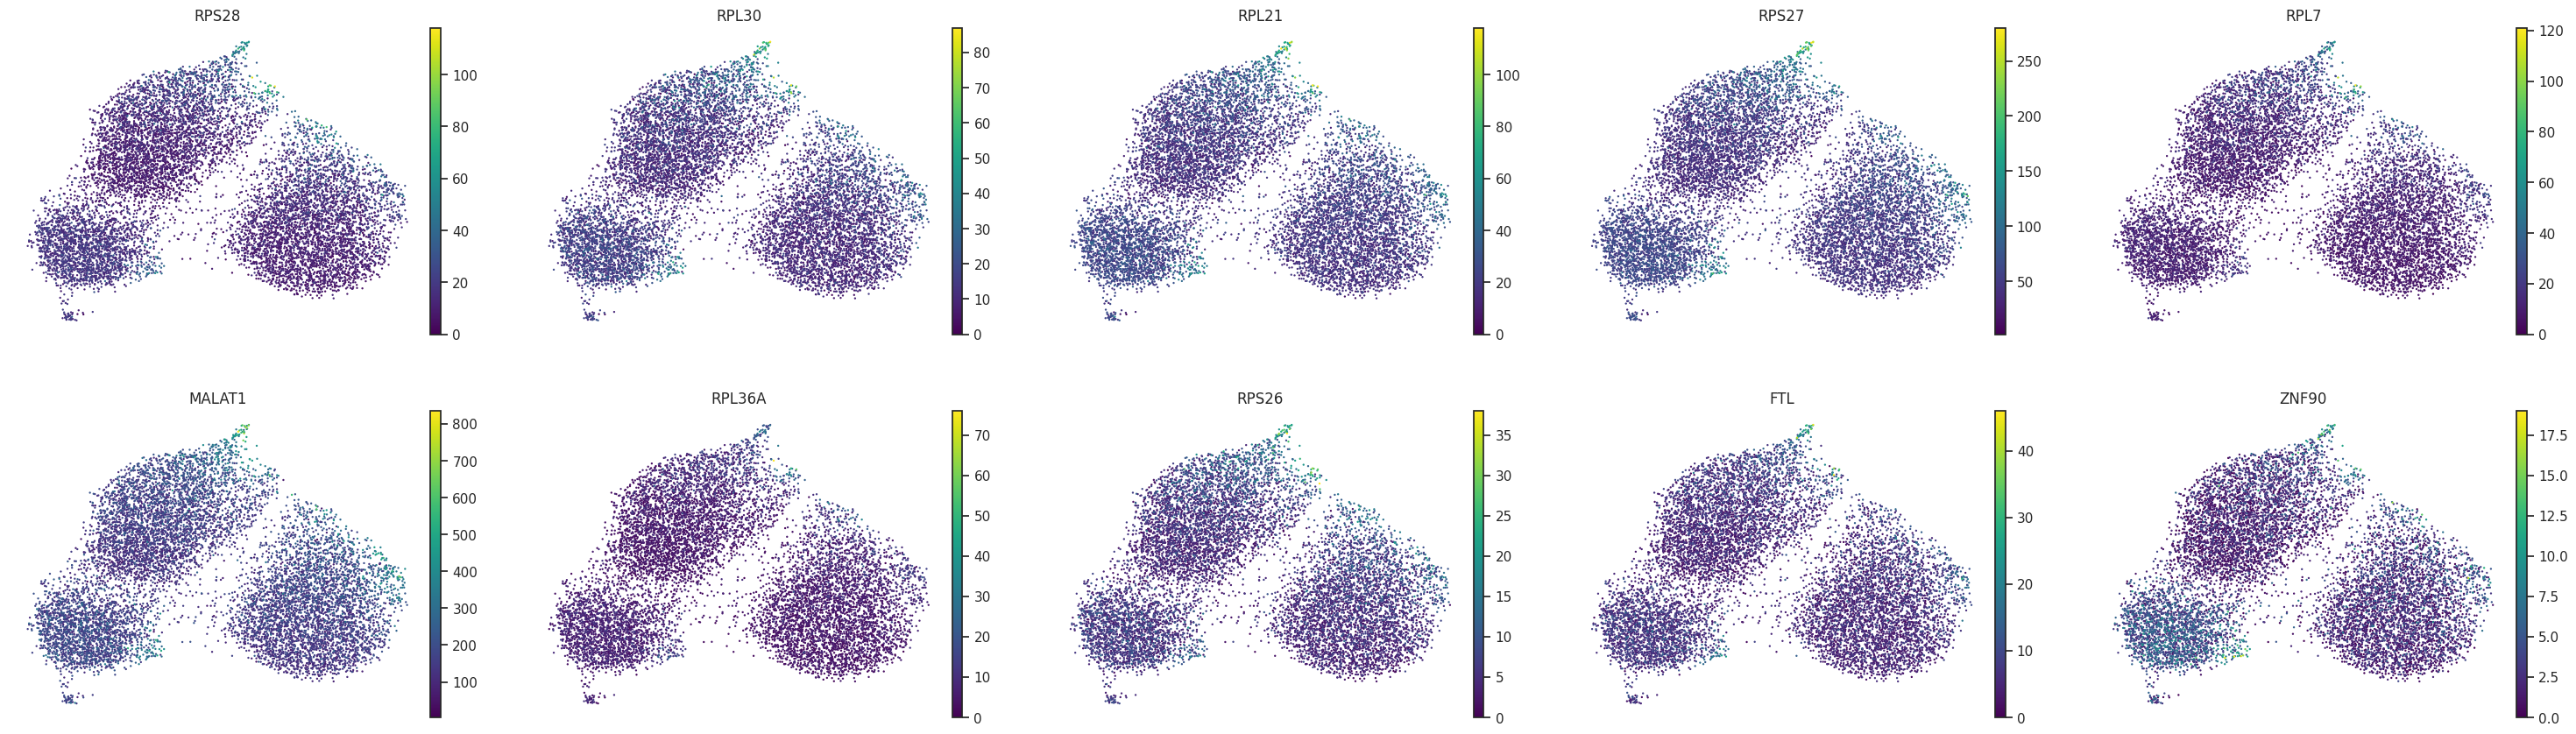

In [59]:
sc.pl.umap(
    adata,
    color=top_genes_fate3,
    ncols=5,
    cmap="viridis",
    frameon=False,
    save="fate3_top10_genes.png"
)


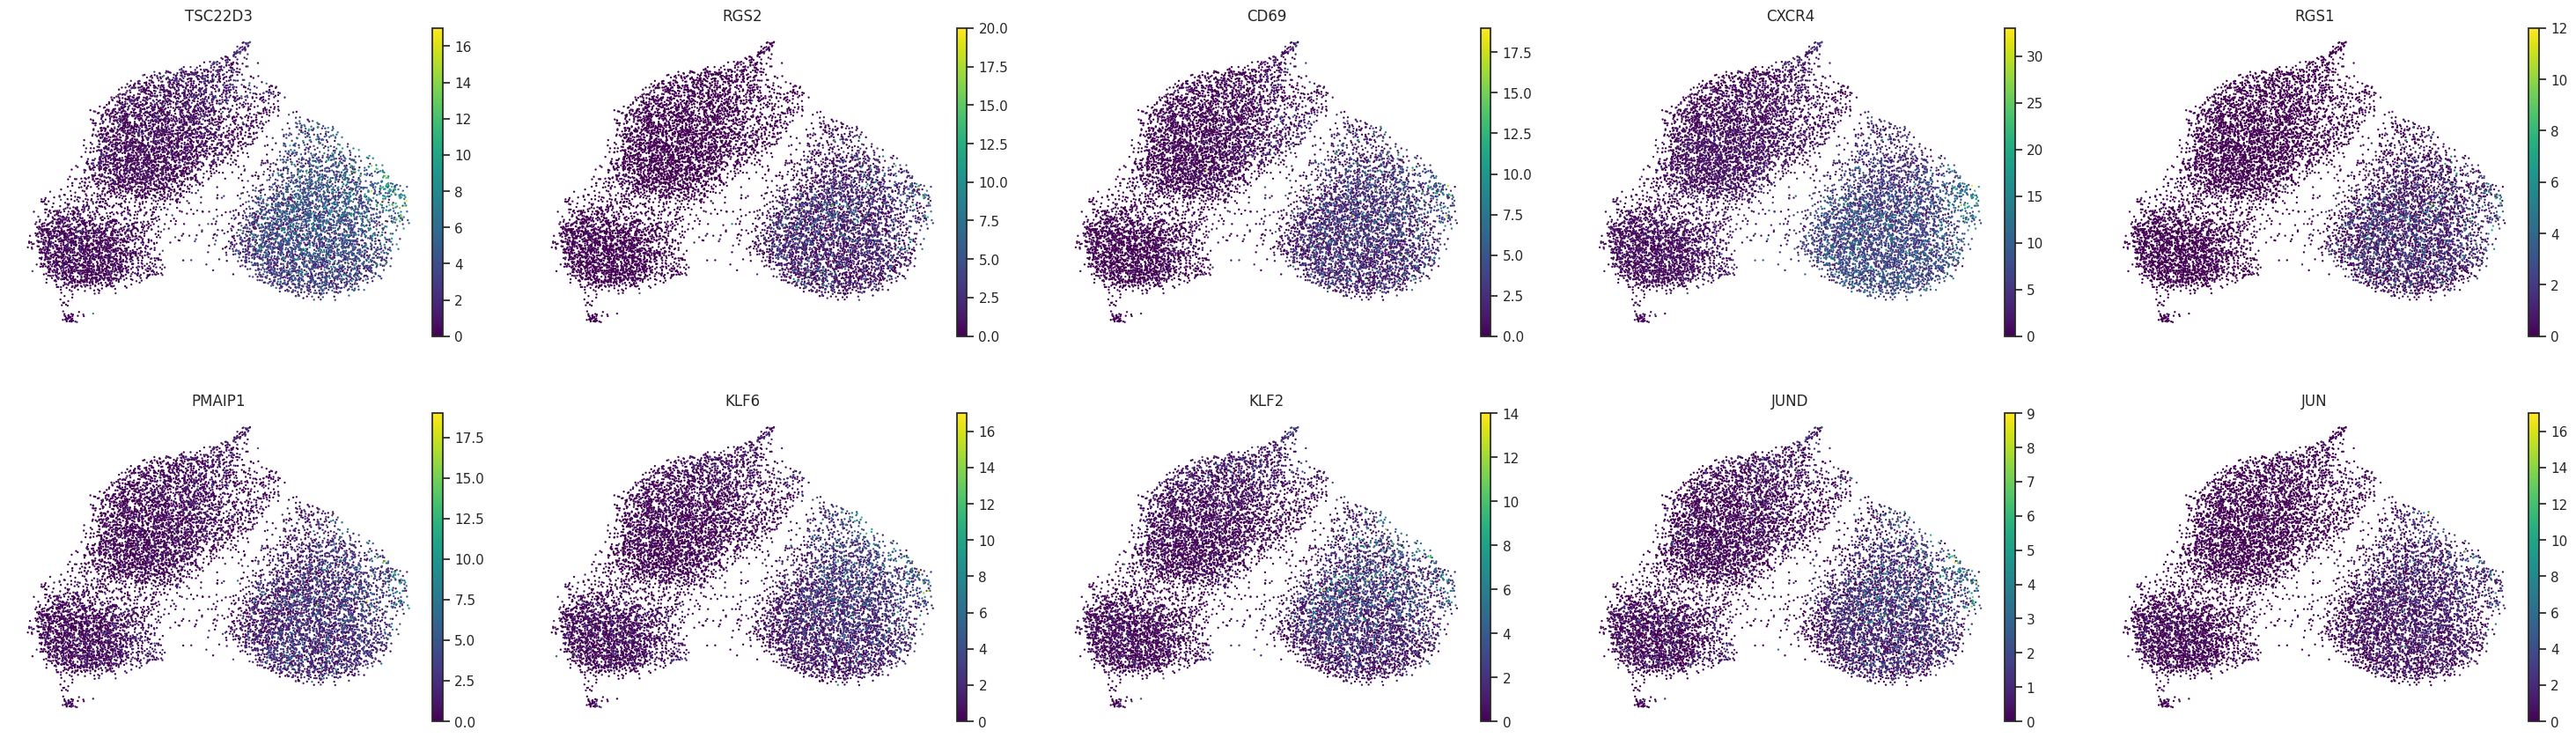

In [58]:
sc.pl.umap(
    adata,
    color=top_genes_fate4,
    ncols=5,
    cmap="viridis",
    frameon=False,
    save="fate4_top10_genes.png"
)

From here and on, the code is not checked and/or validated

In [36]:
cr.pl.aggregate_fate_probabilities(
    adata,
    lineages=["3", "4"],
    basis="umap",
    clusters = adata.obs[["seurat_clusters"]]
)

KeyError: "Key `'clusters'` not found in `adata.obs`."

In [37]:
print(g.terminal_states)

CLL_CPT1_M0_AAACCTGCAATGGACG-1     NaN
CLL_CPT1_M0_AAACCTGCACGAAACG-1     NaN
CLL_CPT1_M0_AAACCTGCACGCTTTC-1     NaN
CLL_CPT1_M0_AAACCTGGTGTTTGTG-1     NaN
CLL_CPT1_M0_AAACCTGTCACCACCT-1     NaN
                                  ... 
CLL_CPT1_M27_TTTGTCAGTAGCCTAT-1    NaN
CLL_CPT1_M27_TTTGTCAGTAGGGTAC-1    NaN
CLL_CPT1_M27_TTTGTCAGTCAAGCGA-1    NaN
CLL_CPT1_M27_TTTGTCATCACGATGT-1    NaN
CLL_CPT1_M27_TTTGTCATCGCCTGAG-1    NaN
Length: 10570, dtype: category
Categories (2, object): ['3', '4']


In [21]:
terminal_state = "3"
g.predict_terminal_states()

GPCCA[kernel=ConnectivityKernel[n=10570], initial_states=['0'], terminal_states=['3', '4']]

In [22]:
g.compute_fate_probabilities()

100%|███████████████████████████████████████████████| 2/2 [00:00<00:00, 11.98/s]


In [23]:
g.compute_lineage_drivers(
    genes=["BCL2"],
    lineages=[terminal_state]
)

,3_corr,3_pval,3_qval,3_ci_low,3_ci_high
RPS28,0.424657,0.000000e+00,0.000000e+00,0.408903,0.440158
RPL30,0.407172,0.000000e+00,0.000000e+00,0.391144,0.422953
RPL21,0.393843,0.000000e+00,0.000000e+00,0.377614,0.409830
RPS27,0.369583,0.000000e+00,0.000000e+00,0.353006,0.385928
MALAT1,0.341013,5.957695e-292,7.447118e-290,0.324055,0.357751
...,...,...,...,...,...
CXCR4,-0.466838,0.000000e+00,0.000000e+00,-0.481616,-0.451795
RGS1,-0.510704,0.000000e+00,0.000000e+00,-0.524660,-0.496473
CD69,-0.528167,0.000000e+00,0.000000e+00,-0.541776,-0.514281
RGS2,-0.536894,0.000000e+00,0.000000e+00,-0.550325,-0.523185


In [24]:
sc.tl.dpt(adata)

    adata.uns['iroot'] = root_cell_index
    adata.var['xroot'] = adata[root_cell_name, :].X
computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.9659893  0.9319698  0.88534343 0.86664635 0.8615302
     0.8321902  0.81309414 0.7902761  0.7754634  0.7533825  0.750496
     0.7398748  0.7342766  0.725566  ]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)
computing Diffusion Pseudotime using n_dcs=10
    finished: added
 (0:00:00)


In [25]:
time_key = "time_point"
time_key

'time_point'

In [26]:
g.compute_lineage_drivers(
    genes=["BCL2"],
    lineages=[terminal_state],
    time_key=time_key  # must pass time_key here
)

,3_corr,3_pval,3_qval,3_ci_low,3_ci_high
RPS28,0.424657,0.000000e+00,0.000000e+00,0.408903,0.440158
RPL30,0.407172,0.000000e+00,0.000000e+00,0.391144,0.422953
RPL21,0.393843,0.000000e+00,0.000000e+00,0.377614,0.409830
RPS27,0.369583,0.000000e+00,0.000000e+00,0.353006,0.385928
MALAT1,0.341013,5.957695e-292,7.447118e-290,0.324055,0.357751
...,...,...,...,...,...
CXCR4,-0.466838,0.000000e+00,0.000000e+00,-0.481616,-0.451795
RGS1,-0.510704,0.000000e+00,0.000000e+00,-0.524660,-0.496473
CD69,-0.528167,0.000000e+00,0.000000e+00,-0.541776,-0.514281
RGS2,-0.536894,0.000000e+00,0.000000e+00,-0.550325,-0.523185


In [27]:
cr.pl.gene_trends(
    adata,
    model=g.lineage_drivers,
    genes=["BCL2"],
    lineages=[terminal_state],
    time_key=time_key,
    same_plot=True
)

TypeError: Class `'DataFrame'` must be of type `BaseModel` or a gene and lineage specific `dict` of `BaseModel`..